# Night selection for V0

What this produces is not "the temperature of Paris", it is a reference pattern. Urban heat island maps in urban climatology are almost always regime maps: "UHI intensity on a clear, calm night". This is deliberate, because it is the critical regime, the one that matters for public health and adaptation. Windy nights pose no health problem: the air mixes and the city cools down. Nobody dies from a windy night. Mapping the worst case is precisely what interests an urban planner. The V0 product is therefore stated honestly as "intensity of the Parisian heat island under favourable conditions", and not as "a universal temperature model".

The two white holes are indeed the Bois de Boulogne and the Bois de Vincennes. Important methodological point: these are the areas where the model will have to extrapolate with no local observation at all. This is exactly why the study area had to cover the whole urban-to-vegetated gradient: the model will learn "dense vegetation = cool" elsewhere (leafy suburbs, peripheral parks) and transpose it. To be flagged as a limitation in the paper, and to be examined closely on the predicted map: if the woods come out cool even though no station said so, that is evidence the model learned physics and not interpolation.

Could an algorithm test all my different parameters and output the ones that give the model with the best RMSE? (=> "The idea is sound in principle: this is a grid search.")


In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import requests

# Notebooks have no __file__: walk up from the working directory to the project root,
# so the notebook works whether the kernel starts in notebooks/ or at the root.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DB_FILE = PROJECT_ROOT / "data" / "uhi_netatmo.sqlite"
LOCAL_TZ = "Europe/Paris"

pd.set_option("display.width", 120)

2 - Load the hourly data per station

In [2]:

# Average the temperatures within each hour for each station ====> why not train the model on the raw data?
query = """
    SELECT station_id,
           CAST(measured_at / 3600 AS INTEGER) * 3600 AS hour_ts,
           AVG(temp_C) AS temp_C
    FROM observations
    WHERE temp_C IS NOT NULL
    GROUP BY station_id, hour_ts
"""
con = sqlite3.connect(DB_FILE)
obsAvgPerHour = pd.read_sql(query, con)
con.close()

obsAvgPerHour["time"] = pd.to_datetime(obsAvgPerHour["hour_ts"], unit="s", utc=True).dt.tz_convert(LOCAL_TZ)
print(f"{len(obsAvgPerHour)} station-hours | {obsAvgPerHour.station_id.nunique()} stations")
print(f"from {obsAvgPerHour.time.min()} to {obsAvgPerHour.time.max()}")
obsAvgPerHour.head()

1628380 station-hours | 3991 stations
from 2026-07-05 13:00:00+02:00 to 2026-08-15 14:00:00+02:00


,station_id,hour_ts,temp_C,time
0,70:ee:50:xx:xx:xx,1783252800,27.025000,2026-07-05 14:00:00+02:00
1,70:ee:50:xx:xx:xx,1783256400,27.866667,2026-07-05 15:00:00+02:00
2,70:ee:50:xx:xx:xx,1783260000,29.240000,2026-07-05 16:00:00+02:00
3,70:ee:50:xx:xx:xx,1783263600,29.525000,2026-07-05 17:00:00+02:00
4,70:ee:50:xx:xx:xx,1783267200,29.100000,2026-07-05 18:00:00+02:00


3 - The hourly spread (the signal metric)

In [3]:
# Group the measurements by hour and compute, across all stations reporting that hour, the median, the 10th and 90th percentiles, the number of stations and the p90-p10 spread
groupedMeasuresHourly = obsAvgPerHour.groupby("time")["temp_C"]
hourlyStats = pd.DataFrame({
    "median": groupedMeasuresHourly.median(),
    "p10": groupedMeasuresHourly.quantile(0.10),
    "p90": groupedMeasuresHourly.quantile(0.90),
    "n_stations": groupedMeasuresHourly.size(),
})
hourlyStats["spread"] = hourlyStats["p90"] - hourlyStats["p10"]
print(f"{len(hourlyStats)} hours recorded ({len(hourlyStats)/24} days)")
hourlyStats.tail()

556 hours recorded (23.166666666666668 days)


,median,p10,p90,n_stations,spread
time,,,,,
2026-08-15 10:00:00+02:00,28.325000,26.500000,30.300000,3060,3.800000
2026-08-15 11:00:00+02:00,29.766667,27.977500,33.597500,3142,5.620000
2026-08-15 12:00:00+02:00,30.300000,28.708333,33.900000,3096,5.191667
2026-08-15 13:00:00+02:00,30.400000,29.000000,32.350000,2891,3.350000
2026-08-15 14:00:00+02:00,31.000000,29.466667,33.033333,2975,3.566667


4 - Fetch the reference weather (Open-Meteo)

In [4]:
start = obsAvgPerHour.time.min().date().isoformat()
end   = obsAvgPerHour.time.max().date().isoformat()

r = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
    "latitude": 48.8566, "longitude": 2.3522,
    "start_date": start, "end_date": end,
    "hourly": "wind_speed_10m,cloud_cover,temperature_2m",
    "timezone": "Europe/Paris",
})
r.raise_for_status()
h = r.json()["hourly"]

weatherPerHour = pd.DataFrame(h)
weatherPerHour["time"] = pd.to_datetime(weatherPerHour["time"]).dt.tz_localize(LOCAL_TZ)
weatherPerHour = weatherPerHour.set_index("time")
weatherPerHour.head()

,wind_speed_10m,cloud_cover,temperature_2m
time,,,
2026-07-05 00:00:00+02:00,13.9,0,21.4
2026-07-05 01:00:00+02:00,11.7,0,20.1
2026-07-05 02:00:00+02:00,10.0,0,19.3
2026-07-05 03:00:00+02:00,8.2,0,18.6
2026-07-05 04:00:00+02:00,8.0,0,18.0


5 - Join and visualise the wind hypothesis

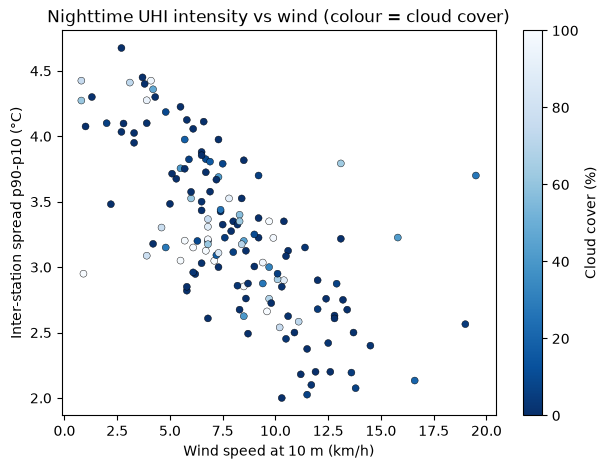

In [5]:
hourlyStatsAndWeather = hourlyStats.join(weatherPerHour[["wind_speed_10m", "cloud_cover"]], how="inner")
hourlyStatsAndWeather["hour"] = hourlyStatsAndWeather.index.hour
hourlyStatsAndWeather["night"] = (hourlyStatsAndWeather.hour >= 23) | (hourlyStatsAndWeather.hour <= 4)   # core of the night

nightsHours = hourlyStatsAndWeather[hourlyStatsAndWeather.night]

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(nightsHours.wind_speed_10m, nightsHours.spread,
                c=nightsHours.cloud_cover, cmap="Blues_r", s=25, edgecolor="k", lw=0.3)
ax.set_xlabel("Wind speed at 10 m (km/h)")
ax.set_ylabel("Inter-station spread p90-p10 (°C)")
ax.set_title("Nighttime UHI intensity vs wind (colour = cloud cover)")
plt.colorbar(sc, label="Cloud cover (%)")
plt.show()

6 - Select the usable nights

In [6]:
WIND_MAX = 10     # km/h
CLOUD_MAX = 100    # % # criteria currently not used
MIN_HOURS = 4

# A "night" spans midnight, so shift by 12 h to group evening + early morning
hourlyStatsAndWeather["night_id"] = (hourlyStatsAndWeather.index - pd.Timedelta(hours=12)).date

nightSummary = hourlyStatsAndWeather[hourlyStatsAndWeather.night].groupby("night_id").agg(
    mean_wind=("wind_speed_10m", "mean"),
    mean_cloud=("cloud_cover", "mean"),
    mean_spread=("spread", "mean"),
    hours=("spread", "size"),
)

# One boolean per criterion: True means the night passes that test
nightSummary["ok_wind"] = nightSummary.mean_wind <= WIND_MAX
nightSummary["ok_cloud"] = nightSummary.mean_cloud <= CLOUD_MAX
nightSummary["ok_hours"] = nightSummary.hours >= MIN_HOURS
nightSummary["selected"] = (
    nightSummary.ok_wind & nightSummary.ok_cloud & nightSummary.ok_hours
)

# --- Rejection breakdown ---------------------------------------------------
n = len(nightSummary)
rej = ~nightSummary.selected

print(f"{n} nights | {nightSummary.selected.sum()} selected | {rej.sum()} rejected\n")
print("Failed each criterion (a night can fail several):")
print(f"  wind  > {WIND_MAX} km/h : {(~nightSummary.ok_wind).sum()}")
print(f"  cloud > {CLOUD_MAX} %   : {(~nightSummary.ok_cloud).sum()}")
print(f"  hours < {MIN_HOURS}       : {(~nightSummary.ok_hours).sum()}")

print("\nSole reason for rejection (isolates each criterion's real cost):")
print(f"  wind only  : {(rej & ~nightSummary.ok_wind & nightSummary.ok_cloud & nightSummary.ok_hours).sum()}")
print(f"  cloud only : {(rej & ~nightSummary.ok_cloud & nightSummary.ok_wind & nightSummary.ok_hours).sum()}")
print(f"  hours only : {(rej & ~nightSummary.ok_hours & nightSummary.ok_wind & nightSummary.ok_cloud).sum()}")
print(f"  several    : {(rej & ((~nightSummary.ok_wind).astype(int) + (~nightSummary.ok_cloud).astype(int) + (~nightSummary.ok_hours).astype(int) > 1)).sum()}")

nightSummary.round(1)

25 nights | 20 selected | 5 rejected

Failed each criterion (a night can fail several):
  wind  > 10 km/h : 5
  cloud > 100 %   : 0
  hours < 4       : 1

Sole reason for rejection (isolates each criterion's real cost):
  wind only  : 4
  cloud only : 0
  hours only : 0
  several    : 1


,mean_wind,mean_cloud,mean_spread,hours,ok_wind,ok_cloud,ok_hours,selected
night_id,,,,,,,,
2026-07-05,7.1,83.5,3.2,6,True,True,True,True
2026-07-06,3.2,40.3,4.2,6,True,True,True,True
2026-07-07,7.8,32.7,3.5,6,True,True,True,True
2026-07-08,9.4,0.0,2.5,4,True,True,True,True
2026-07-09,12.1,0.7,2.2,3,False,True,False,False
2026-07-26,13.8,3.8,2.6,6,False,True,True,False
2026-07-27,5.6,0.0,2.9,6,True,True,True,True
2026-07-28,5.0,0.0,3.8,6,True,True,True,True
2026-07-29,7.2,0.0,3.5,6,True,True,True,True


7 - Filter the observations to the selected nights

In [7]:
CORE_HOURS = [0, 1, 2, 3, 4]     # hours when the contrast is established

selectedNights = set(nightSummary.index[nightSummary.selected])

obsAvgPerHour["night_id"] = (obsAvgPerHour.time - pd.Timedelta(hours=12)).dt.date
obsAvgPerHour["hour"] = obsAvgPerHour.time.dt.hour

filteredObsAvgPerHour = obsAvgPerHour[
    obsAvgPerHour.night_id.isin(selectedNights)
    & obsAvgPerHour.hour.isin(CORE_HOURS)
].copy()

print(f"{len(filteredObsAvgPerHour)} station-hours over {filteredObsAvgPerHour.night_id.nunique()} nights")
print(f"{filteredObsAvgPerHour.station_id.nunique()} distinct stations")

287190 station-hours over 20 nights
3935 distinct stations


8 - Compute the hourly anomaly

In [8]:
# City reference for each hour: median across all reporting stations
city_median = filteredObsAvgPerHour.groupby("time")["temp_C"].transform("median")
filteredObsAvgPerHour["anomaly"] = filteredObsAvgPerHour["temp_C"] - city_median

print(city_median.nunique())                # one distinct value per selected hour ===> city_median holds the median of each core hour of each selected night, repeated for every station reporting that hour
filteredObsAvgPerHour["anomaly"].describe().round(2)

#print(len(city_median), len(core))          # identical

94


count    287190.00
mean         -0.06
std           1.47
min         -51.65
25%          -0.86
50%           0.00
75%           0.84
max          12.42
Name: anomaly, dtype: float64

9 - Aggregate per station and filter on coverage

In [9]:
MIN_NIGHTS = 4    # a station must appear on at least this many nights

statsPerStation = filteredObsAvgPerHour.groupby("station_id").agg(
    anomaly_mean=("anomaly", "mean"),
    anomaly_std=("anomaly", "std"),
    n_hours=("anomaly", "size"),
    n_nights=("night_id", "nunique"),
)
statsPerStationFiltered = statsPerStation[statsPerStation.n_nights >= MIN_NIGHTS].copy()

print(f"{len(statsPerStationFiltered)} stations kept out of {len(statsPerStation)}")
statsPerStationFiltered.describe().round(2)

3817 stations kept out of 3935


,anomaly_mean,anomaly_std,n_hours,n_nights
count,3817.00,3817.00,3817.00,3817.00
mean,-0.08,0.65,75.04,17.20
std,1.37,0.41,25.66,4.39
min,-6.14,0.13,4.00,4.00
25%,-0.92,0.40,60.00,16.00
50%,-0.02,0.54,87.00,20.00
75%,0.82,0.77,96.00,20.00
max,7.54,6.35,97.00,20.00


10 - A first simple but effective quality control

In [10]:
# Stations whose anomaly is wildly inconsistent across nights are suspicious
# (badly sited sensors, indoor modules, etc.)
STD_MAX = statsPerStationFiltered.anomaly_std.quantile(0.95)
ANOM_LIMIT = 6.0   # °C, physically implausible for a city-scale anomaly

statsPerStationFiltered2 = statsPerStationFiltered[
    (statsPerStationFiltered.anomaly_std < STD_MAX)
    & (statsPerStationFiltered.anomaly_mean.abs() < ANOM_LIMIT)
].copy()

print(f"{len(statsPerStationFiltered2)} stations after QC ({len(statsPerStationFiltered) - len(statsPerStationFiltered2)} dropped)")
statsPerStationFiltered2.anomaly_mean.describe().round(2)

3625 stations after QC (192 dropped)


count    3625.00
mean       -0.04
std         1.27
min        -5.44
25%        -0.87
50%        -0.01
75%         0.82
max         4.65
Name: anomaly_mean, dtype: float64

11 - The truth map: the signal, visually

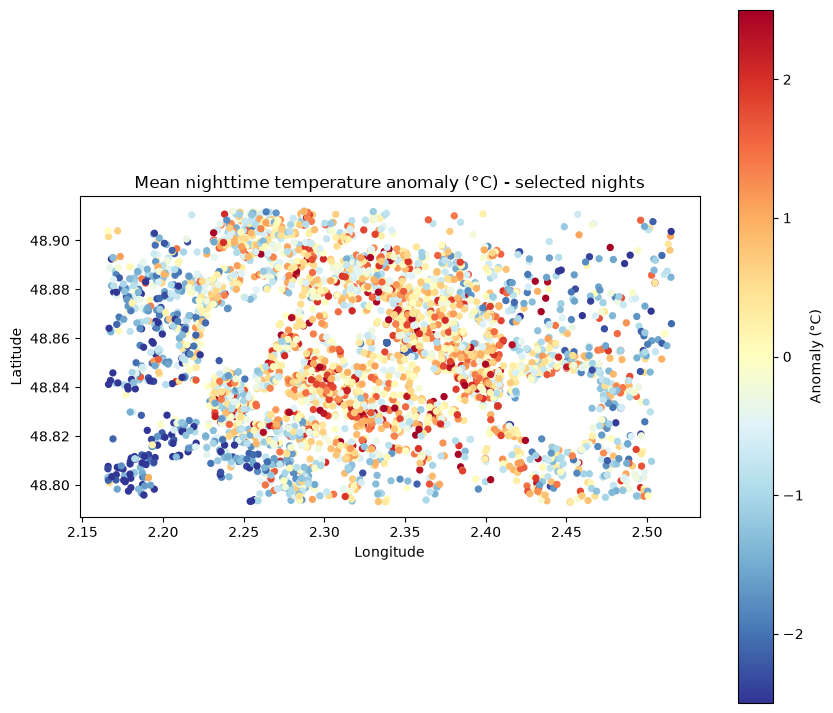

In [11]:
import sqlite3
con = sqlite3.connect(DB_FILE)
coords = pd.read_sql("SELECT station_id, lat, lon, altitude FROM stations", con)
con.close()

finalSelectedStations = statsPerStationFiltered2.merge(coords, on="station_id")

fig, ax = plt.subplots(figsize=(10, 9))
sc = ax.scatter(finalSelectedStations.lon, finalSelectedStations.lat, c=finalSelectedStations.anomaly_mean,
                cmap="RdYlBu_r", s=18, vmin=-2.5, vmax=2.5)
ax.set_aspect(1 / 0.66)      # rough aspect correction at Paris latitude
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Mean nighttime temperature anomaly (°C) - selected nights")
plt.colorbar(sc, label="Anomaly (°C)")
plt.show()

Statistical check of the features

In [12]:
import sqlite3
import pandas as pd

con = sqlite3.connect(DB_FILE)
stationFeatures = pd.read_sql("SELECT * FROM station_features", con)
con.close()

print(stationFeatures.shape)
print(stationFeatures.isna().sum())          # missing values per column
stationFeatures.describe().round(3)

(3967, 12)
station_id           0
altitude             0
built_frac_100       0
mean_height_100    212
veg_frac_100         0
built_frac_250       0
mean_height_250      0
veg_frac_250         0
built_frac_500       0
mean_height_500      0
veg_frac_500         0
dist_water_m         0
dtype: int64


,altitude,built_frac_100,mean_height_100,veg_frac_100,built_frac_250,mean_height_250,veg_frac_250,built_frac_500,mean_height_500,veg_frac_500,dist_water_m
count,3967.000,3967.000,3755.000,3967.000,3967.000,3967.000,3967.000,3967.000,3967.000,3967.000,3967.000
mean,59.060,0.342,14.836,0.081,0.336,14.690,0.087,0.328,14.762,0.099,514.701
std,25.701,0.155,5.791,0.120,0.125,4.992,0.093,0.112,4.493,0.092,361.210
min,16.000,0.000,0.000,0.000,0.016,2.064,0.000,0.023,4.928,0.000,0.000
25%,41.000,0.241,10.443,0.000,0.244,10.526,0.024,0.247,11.162,0.037,233.150
50%,51.000,0.344,15.166,0.043,0.329,15.403,0.065,0.325,15.461,0.079,469.807
75%,69.000,0.452,18.610,0.109,0.425,18.300,0.113,0.396,18.085,0.129,737.115
max,273.000,0.789,79.531,0.813,0.667,67.381,0.723,0.648,49.118,0.874,2005.191


Physical consistency check of the features

In [13]:
# Built and vegetated fractions should be strongly anti-correlated
stationFeatures[[c for c in stationFeatures.columns if c.startswith(("built", "veg", "mean_h"))]].corr().round(2)

,built_frac_100,mean_height_100,veg_frac_100,built_frac_250,mean_height_250,veg_frac_250,built_frac_500,mean_height_500,veg_frac_500
built_frac_100,1.00,0.29,-0.44,0.88,0.30,-0.39,0.69,0.30,-0.30
mean_height_100,0.29,1.00,0.08,0.37,0.86,0.02,0.41,0.78,-0.06
veg_frac_100,-0.44,0.08,1.00,-0.37,-0.08,0.83,-0.30,-0.02,0.64
built_frac_250,0.88,0.37,-0.37,1.00,0.41,-0.44,0.89,0.43,-0.39
mean_height_250,0.30,0.86,-0.08,0.41,1.00,-0.10,0.52,0.93,-0.18
veg_frac_250,-0.39,0.02,0.83,-0.44,-0.10,1.00,-0.39,-0.06,0.86
built_frac_500,0.69,0.41,-0.30,0.89,0.52,-0.39,1.00,0.55,-0.47
mean_height_500,0.30,0.78,-0.02,0.43,0.93,-0.06,0.55,1.00,-0.14
veg_frac_500,-0.30,-0.06,0.64,-0.39,-0.18,0.86,-0.47,-0.14,1.00


Visual check of the features

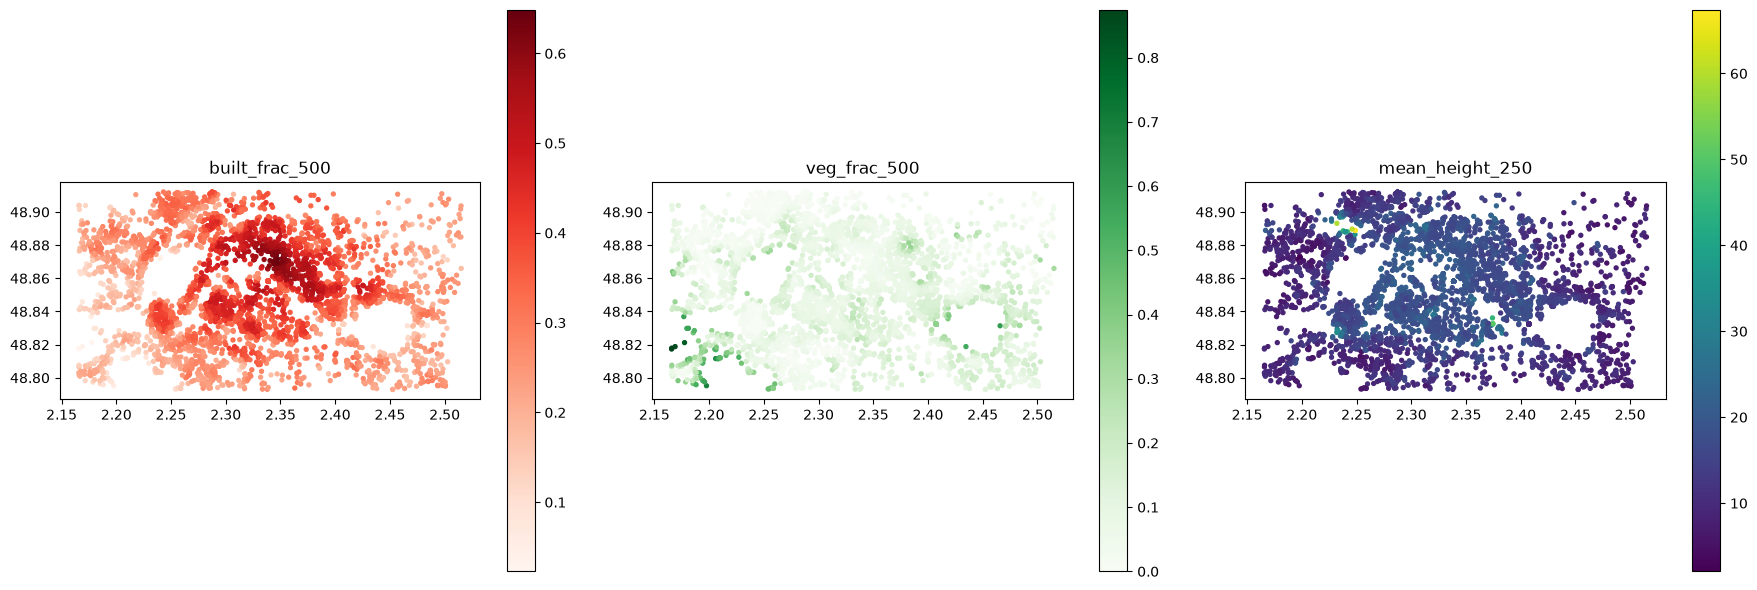

In [14]:
coords = pd.read_sql("SELECT station_id, lat, lon FROM stations", sqlite3.connect(DB_FILE))
fv = stationFeatures.merge(coords, on="station_id")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col, cmap in zip(axes,
                         ["built_frac_500", "veg_frac_500", "mean_height_250"],
                         ["Reds", "Greens", "viridis"]):
    sc = ax.scatter(fv.lon, fv.lat, c=fv[col], cmap=cmap, s=8)
    ax.set_aspect(1 / 0.66)
    ax.set_title(col)
    plt.colorbar(sc, ax=ax)
plt.tight_layout(); plt.show()

12 - Assemble X and y

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# `finalSelectedStations` already holds the target (anomaly_mean) plus lat/lon from cell 11. "altitude" is dropped because it is already included in stationFeatures
data = finalSelectedStations.drop(columns=["altitude"]).merge(stationFeatures, on="station_id", how="inner")

# No buildings within a buffer -> mean height is undefined, not missing data
for c in [c for c in data.columns if c.startswith("mean_height")]:
    data[c] = data[c].fillna(0)

FEATURES = [c for c in data.columns
            if c.startswith(("built_frac", "veg_frac", "mean_height"))] \
           + ["dist_water_m", "altitude"]

data = data.dropna(subset=FEATURES + ["anomaly_mean"]) # TODO: check whether rows get dropped here, and why

X = data[FEATURES]
y = data["anomaly_mean"]
print(f"{len(data)} stations | {len(FEATURES)} features")
print(FEATURES)


3621 stations | 11 features
['built_frac_100', 'mean_height_100', 'veg_frac_100', 'built_frac_250', 'mean_height_250', 'veg_frac_250', 'built_frac_500', 'mean_height_500', 'veg_frac_500', 'dist_water_m', 'altitude']


Cell 13 - The spatial blocks (the validation protocol)

In [16]:
BLOCK_SIZE_DEG = 0.02          # roughly 1.5 km blocks

data["block"] = (
    (data.lat / BLOCK_SIZE_DEG).astype(int).astype(str) + "_" +
    (data.lon / BLOCK_SIZE_DEG).astype(int).astype(str)
)
groups = data["block"]
print(f"{groups.nunique()} spatial blocks, "
      f"median {int(groups.value_counts().median())} stations each")

119 spatial blocks, median 24 stations each


Cell 14 - The baselines (to do BEFORE the model)

In [17]:
from scipy.spatial import cKDTree

# Baseline 1: predict the mean anomaly everywhere
pred_mean = np.full(len(y), y.mean())

# Baseline 2: copy the nearest station (excluding same-block neighbours)
coords_arr = data[["lat", "lon"]].values
pred_nn = np.empty(len(y))
gkf = GroupKFold(n_splits=5)
for train_idx, test_idx in gkf.split(X, y, groups):
    tree = cKDTree(coords_arr[train_idx])
    _, nn = tree.query(coords_arr[test_idx])
    pred_nn[test_idx] = y.values[train_idx][nn]

def report(name, pred):
    mae = mean_absolute_error(y, pred)
    rmse = np.sqrt(mean_squared_error(y, pred))
    print(f"{name:<22} MAE={mae:.3f}  RMSE={rmse:.3f}")

report("Baseline: mean", pred_mean)
report("Baseline: nearest st.", pred_nn)

Baseline: mean         MAE=1.005  RMSE=1.273
Baseline: nearest st.  MAE=1.194  RMSE=1.529


Cell 15 - The Random Forest under spatial validation

In [18]:
rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    n_jobs=-1,
    random_state=42,
)

pred_rf = cross_val_predict(rf, X, y, groups=groups, cv=GroupKFold(n_splits=5), n_jobs=1)
report("Random Forest (spatial CV)", pred_rf)

# For contrast only: the optimistic number a naive random CV would give
from sklearn.model_selection import KFold
pred_naive = cross_val_predict(rf, X, y, cv=KFold(5, shuffle=True, random_state=0))
report("RF with random CV (leaky!)", pred_naive)

Random Forest (spatial CV) MAE=0.900  RMSE=1.143
RF with random CV (leaky!) MAE=0.870  RMSE=1.092


Cell 16 - Feature importance

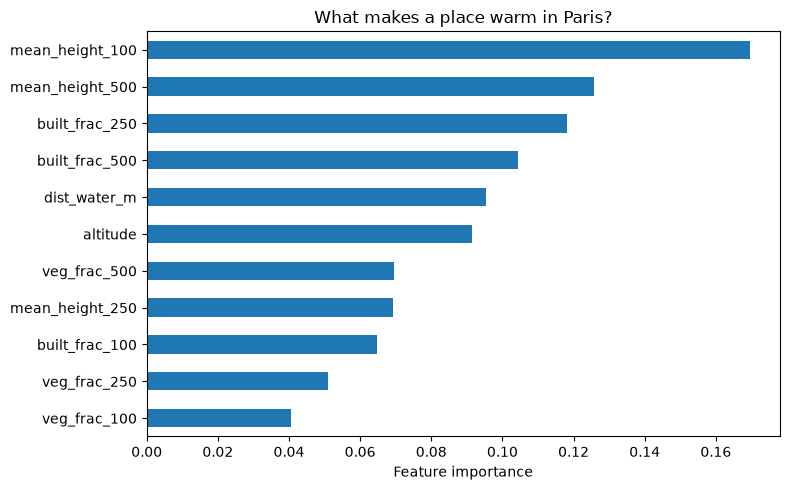

mean_height_100    0.170
mean_height_500    0.126
built_frac_250     0.118
built_frac_500     0.104
dist_water_m       0.095
altitude           0.091
veg_frac_500       0.070
mean_height_250    0.069
built_frac_100     0.065
veg_frac_250       0.051
veg_frac_100       0.041
dtype: float64

In [19]:
rf.fit(X, y)
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
imp.plot.barh(ax=ax)
ax.set_xlabel("Feature importance")
ax.set_title("What makes a place warm in Paris?")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3)

4. Predict on a grid: the first map. This is where the project becomes visual. Generate a regular grid over Paris (say 100 m), recompute the same features for each cell (direct reuse of the feature code, replacing the station points with cell centres), predict, display. Note that this step takes as long as the station features, or longer, depending on the resolution.

After that the full loop exists, and that is when fine-tuning becomes possible and useful: adjust MIN_NIGHTS, WIND_MAX and CORE_HOURS while measuring their effect on performance, add the BD TOPO features identified earlier (materials, dwellings), harden the QC. Each change becomes a measurable experiment instead of an intuition.

Advice: do steps 1 to 3 in this notebook as soon as the script finishes, even with an imperfect dataset. Seeing the first feature importance and the first RMSE changes the whole relationship to the project, and it will reveal the remaining bugs while collection continues.


In [24]:
finalSelectedStations[["station_id", "anomaly_mean"]].to_csv(PROJECT_ROOT / "data" / "station_target.csv", index=False)

grid_pred = pd.read_csv(PROJECT_ROOT / "data" / "grid_prediction_200m.csv")
print(grid_pred.prediction.describe())

count    12321.000000
mean        -0.512722
std          0.724437
min         -2.664651
25%         -1.049795
50%         -0.467990
75%          0.016333
max          1.794693
Name: prediction, dtype: float64


A last point to watch: the grainy texture (isolated blue cells in the middle of light areas) reveals a strong sensitivity to very local feature variations. Part of it is real (a block of buildings vs a small square), part of it is estimation noise. It is visually less clean than a properly smoothed map.